# Systemy AI – Laboratorium 7
## Zadanie: klasyfikator softmax w PyTorch – pingwiny

Napisz samodzielnie w PyTorch klasyfikator softmax, który rozpoznaje **gatunek pingwina** (Adelie, Chinstrap, Gentoo) na podstawie **dwóch** cech: długości i wysokości dzioba. Znasz te dane z Lab 4 – tym razem nie używasz gotowego `fit`, tylko sam(a) piszesz pętlę uczenia. Wzoruj się na notatniku `SystemyAI_Lab7_wzor.ipynb`.

Dwie cechy wybraliśmy celowo: wynik da się narysować na płaszczyźnie, a zadanie nie jest trywialne (Adelie i Chinstrap częściowo na siebie nachodzą).

**Zasady** (jak poprzednio): nazwy zmiennych z treści są obowiązkowe; komórek `# TEST` nie zmieniaj; przed oddaniem *Uruchom ponownie i uruchom wszystko*.

---
## 1. Dane → tensory
1. Wczytaj `sns.load_dataset("penguins")`, zostaw wiersze bez braków w `bill_length_mm`, `bill_depth_mm`, `species`.
2. Zamień gatunki na liczby: `gatunki = ["Adelie", "Chinstrap", "Gentoo"]` → 0, 1, 2.
3. Podział **trzyczęściowy** (dwa razy `train_test_split`, `stratify`, `random_state=42`): najpierw 20% na test, potem z reszty 25% na walidację. Wyjdzie 204 / 69 / 69.
4. `StandardScaler` dopasowany **tylko** na train; przekształć wszystkie trzy zbiory.
5. Tensory: `X_tr`, `X_va`, `X_te` (`float32`) oraz `y_tr`, `y_va`, `y_te` (`long`).

Zbiór walidacyjny posłuży do krzywych uczenia i wyboru learning rate, testowy – raz, na końcu.

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import (
  DataLoader, TensorDataset
)


import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

In [2]:
df = sns.load_dataset("penguins")
cechy = ["bill_length_mm", "bill_depth_mm"]
df = df.dropna(subset=cechy + ["species"]).reset_index(drop=True)

gatunki = ["Adelie", "Chinstrap", "Gentoo"]
mapa = {g: i for i, g in enumerate(gatunki)}
X = df[cechy].to_numpy()
y = df["species"].map(mapa).to_numpy()

X_tmp, X_test, y_tmp, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
X_train, X_val, y_train, y_val = train_test_split(
    X_tmp, y_tmp, test_size=0.25, stratify=y_tmp, random_state=42
)
print(f"train / val / test: {len(X_train)} / {len(X_val)} / {len(X_test)}")

scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_val_s = scaler.transform(X_val)
X_test_s = scaler.transform(X_test)

X_tr = torch.tensor(X_train_s, dtype=torch.float32)
X_va = torch.tensor(X_val_s, dtype=torch.float32)
X_te = torch.tensor(X_test_s, dtype=torch.float32)
y_tr = torch.tensor(y_train, dtype=torch.long)
y_va = torch.tensor(y_val, dtype=torch.long)
y_te = torch.tensor(y_test, dtype=torch.long)

print(X_tr.shape, X_tr.dtype, y_tr.shape, y_tr.dtype)
print("średnie train po skalowaniu:", X_tr.mean(0))
print("liczności klas w train:", torch.bincount(y_tr))

train / val / test: 204 / 69 / 69
torch.Size([204, 2]) torch.float32 torch.Size([204]) torch.int64
średnie train po skalowaniu: tensor([-2.3374e-09, -2.3374e-09])
liczności klas w train: tensor([91, 40, 73])


In [3]:
# TEST
assert X_tr.shape == (204, 2) and X_va.shape == (69, 2) and X_te.shape == (69, 2)
assert X_tr.dtype == torch.float32 and y_tr.dtype == torch.long
assert set(y_tr.tolist()) == {0, 1, 2}
assert torch.allclose(X_tr.mean(dim=0), torch.zeros(2), atol=1e-5), "Standaryzacja dopasowana na train"
print("1 OK")

1 OK


---
## 2. Model i strata przed uczeniem
1. `torch.manual_seed(0)`, potem `model = nn.Linear(2, 3)` i `loss_fn = nn.CrossEntropyLoss()`.
2. Policz `loss0` – stratę na zbiorze treningowym **przed** uczeniem (`.item()`).
3. Policz `p0` – prawdopodobieństwa (softmax) dla pierwszych 3 pingwinów treningowych i wypisz je.

In [4]:
torch.manual_seed(0)
model = nn.Linear(2, 3)
loss_fn = nn.CrossEntropyLoss()

with torch.no_grad():
    logits0 = model(X_tr)
    loss0 = loss_fn(logits0, y_tr).item()
    p0 = torch.softmax(logits0[:3], dim=1)

print(f"loss0 = {loss0:.4f}")
print("p0 =", p0)

loss0 = 1.5298
p0 = tensor([[0.1938, 0.5522, 0.2539],
        [0.3298, 0.3845, 0.2857],
        [0.4144, 0.2371, 0.3485]])


In [5]:
# TEST
assert 0.8 < loss0 < 2.0
assert torch.allclose(p0.sum(dim=1), torch.ones(3))
print("2 OK")

2 OK


*Twoja odpowiedź:* model, który dla każdego pingwina daje wszystkim trzem gatunkom prawdopodobieństwo 1/3, ma stratę dokładnie ln 3 ≈ 1.10. Dlaczego? Czy twoja `loss0` jest blisko tej wartości?

> Entropia krzyżowa to średnia z ln(prawdopodobieństwa prawdziwej klasy). Gdy każda klasa dostaje 1/3, każdy składnik wynosi ln(1/3) = ln 3 ≈ 1.10, więc średnia też.

> `loss0` = 1.53

---
## 3. Pętla uczenia
Napisz funkcję `train(lr, epochs=100, batch_size=32, X=X_tr, seed=0, X_val=X_va)`, która:
- ustawia `torch.manual_seed(seed)` i tworzy **nowy** `nn.Linear(2, 3)`, `CrossEntropyLoss` i `optim.SGD(..., lr=lr)`,
- uczy model mini-batchami (`DataLoader` z `shuffle=True`) przez `epochs` epok,
- po każdej epoce zapisuje w słowniku `historia` trzy listy: `"train loss"` (na `X`), `"val loss"` i `"val acc"` (na `X_val`); parametry `X` i `X_val` przydadzą się w punkcie 5,
- zwraca `(model, historia)`.

Uruchom ją dla `lr=0.1` (`model_01, hist_01`) i narysuj dwa wykresy: straty train/val oraz accuracy val w funkcji epoki.

po 100 epokach: train loss = 0.1233, val loss = 0.1492, val acc = 0.9710


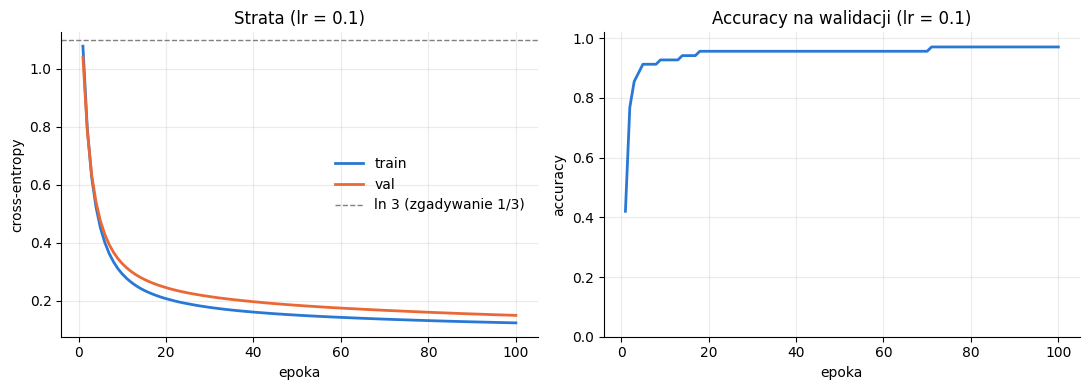

In [6]:
def train(lr, epochs=100, batch_size=32, X=X_tr, seed=0, X_val=X_va):
  torch.manual_seed(seed)
  model = nn.Linear(2, 3)
  loss_fn = nn.CrossEntropyLoss()
  optimizer = optim.SGD(model.parameters(), lr=lr)

  loader = DataLoader(TensorDataset(X, y_tr), batch_size=batch_size, shuffle=True)
  historia = {"train loss": [], "val loss": [], "val acc": []}

  for epoka in range(epochs):
    model.train()
    for xb, yb in loader:
      optimizer.zero_grad()
      loss = loss_fn(model(xb), yb)
      loss.backward()
      optimizer.step()

    model.eval()
    with torch.no_grad():
      historia["train loss"].append(loss_fn(model(X), y_tr).item())
      logits_val = model(X_val)
      historia["val loss"].append(loss_fn(logits_val, y_va).item())
      acc = (logits_val.argmax(dim=1) == y_va).float().mean().item()
      historia["val acc"].append(acc)

  return model, historia


model_01, hist_01 = train(lr=0.1)

print(f"po 100 epokach: train loss = {hist_01['train loss'][-1]:.4f}, "
      f"val loss = {hist_01['val loss'][-1]:.4f}, "
      f"val acc = {hist_01['val acc'][-1]:.4f}")

epoki = range(1, len(hist_01["train loss"]) + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

ax1.plot(epoki, hist_01["train loss"], color="#2a78d6", lw=2, label="train")
ax1.plot(epoki, hist_01["val loss"], color="#eb6834", lw=2, label="val")
ax1.axhline(torch.log(torch.tensor(3.0)).item(), color="gray", lw=1, ls="--",
            label="ln 3 (zgadywanie 1/3)")
ax1.set(title="Strata (lr = 0.1)", xlabel="epoka", ylabel="cross-entropy")
ax1.legend(frameon=False)

ax2.plot(epoki, hist_01["val acc"], color="#2a78d6", lw=2)
ax2.set(title="Accuracy na walidacji (lr = 0.1)", xlabel="epoka",
        ylabel="accuracy", ylim=(0, 1.02))

for ax in (ax1, ax2):
  ax.grid(alpha=0.25)
  ax.spines[["top", "right"]].set_visible(False)

fig.tight_layout()

In [7]:
# TEST
assert set(hist_01) == {"train loss", "val loss", "val acc"} and len(hist_01["val acc"]) == 100
assert hist_01["train loss"][-1] < hist_01["train loss"][0], "Strata powinna maleć"
assert hist_01["val acc"][-1] > 0.9
print("3 OK")

3 OK


---
## 4. Learning rate
Naucz model dla `lr` ∈ {0.001, 0.01, 0.1, 1.0}. Na jednym wykresie narysuj krzywe **straty treningowej** dla wszystkich czterech wartości, a wyniki końcowe (`val loss`, `val acc` po 100 epokach) zbierz w `pd.DataFrame` o nazwie `wyniki_lr` (indeks: wartości lr).

       val loss  val acc
lr                      
0.001    1.0382   0.4203
0.010    0.3294   0.9275
0.100    0.1492   0.9710
1.000    0.0724   0.9710


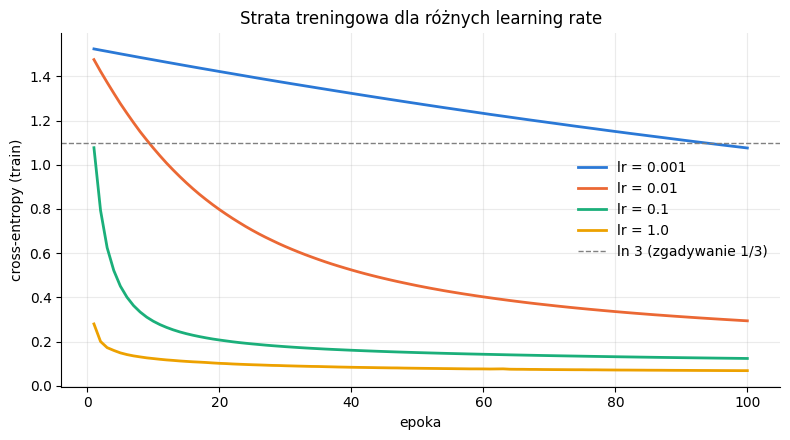

In [8]:
lrs = [0.001, 0.01, 0.1, 1.0]
historie = {}
for lr in lrs:
    _, historie[lr] = train(lr=lr)

wyniki_lr = pd.DataFrame(
    {
        "val loss": [historie[lr]["val loss"][-1] for lr in lrs],
        "val acc": [historie[lr]["val acc"][-1] for lr in lrs],
    },
    index=pd.Index(lrs, name="lr"),
)
print(wyniki_lr.round(4))

kolory = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
epoki = range(1, 101)

fig, ax = plt.subplots(figsize=(8, 4.5))
for lr, kolor in zip(lrs, kolory):
    ax.plot(epoki, historie[lr]["train loss"], color=kolor, lw=2, label=f"lr = {lr}")
ax.axhline(torch.log(torch.tensor(3.0)).item(), color="gray", lw=1, ls="--",
           label="ln 3 (zgadywanie 1/3)")
ax.set(title="Strata treningowa dla różnych learning rate",
       xlabel="epoka", ylabel="cross-entropy (train)")
ax.legend(frameon=False)
ax.grid(alpha=0.25)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()

In [9]:
# TEST
assert list(wyniki_lr.index) == [0.001, 0.01, 0.1, 1.0]
assert wyniki_lr.loc[0.001, "val loss"] > wyniki_lr.loc[0.1, "val loss"]
print("4 OK")

4 OK


*Twoja odpowiedź:* co widać dla lr = 0.001? Który learning rate wybierasz i na podstawie którego zbioru?

> Dla lr = 0.001 strata spada bardzo wolno, prawie liniowo, z 1.52 do 1.08 przez 100 epok. Dopiero pod koniec schodzi poniżej ln 3, więc model jest niewiele lepszy od zgadywania 1/3 (`val acc` 0.42).

> Wybieram lr = 1.0, na podstawie zbioru walidacyjnego. `val acc` jest równe dla 0.1 i 1.0 (0.971), więc decyduje `val loss`, a ten jest najniższy dla 1.0 (0.072 wobec 0.149).

---
## 5. Co daje standaryzacja?
Utwórz `X_tr_raw` i `X_va_raw` – tensory **bez** standaryzacji (surowe milimetry z `X_train`, `X_val`) i naucz model z `lr=0.1`: `train(0.1, X=X_tr_raw, X_val=X_va_raw)`. Porównaj końcową stratę i accuracy z wynikiem z punktu 3. Wynik zapisz w `hist_raw`.

                        train loss  val loss  val acc
standaryzowane (pkt 3)      0.1233    0.1492   0.9710
surowe mm                  27.6107   29.0971   0.7971


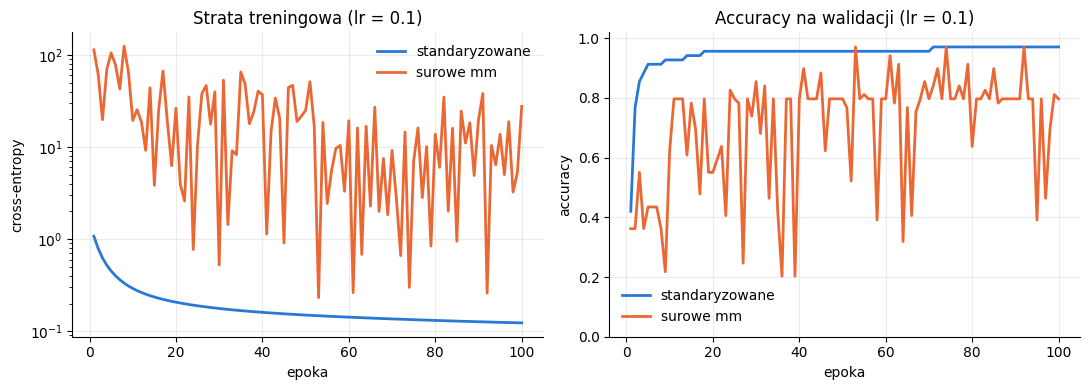

In [10]:
X_tr_raw = torch.tensor(X_train, dtype=torch.float32)  # surowe milimetry
X_va_raw = torch.tensor(X_val, dtype=torch.float32)

model_raw, hist_raw = train(0.1, X=X_tr_raw, X_val=X_va_raw)

porownanie = pd.DataFrame(
  {
    "train loss": [hist_01["train loss"][-1], hist_raw["train loss"][-1]],
    "val loss": [hist_01["val loss"][-1], hist_raw["val loss"][-1]],
    "val acc": [hist_01["val acc"][-1], hist_raw["val acc"][-1]],
  },
  index=["standaryzowane (pkt 3)", "surowe mm"],
)
print(porownanie.round(4))

epoki = range(1, 101)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

ax1.plot(epoki, hist_01["train loss"], color="#2a78d6", lw=2, label="standaryzowane")
ax1.plot(epoki, hist_raw["train loss"], color="#eb6834", lw=2, label="surowe mm")
ax1.set(title="Strata treningowa (lr = 0.1)", xlabel="epoka", ylabel="cross-entropy",
        yscale="log")
ax1.legend(frameon=False)

ax2.plot(epoki, hist_01["val acc"], color="#2a78d6", lw=2, label="standaryzowane")
ax2.plot(epoki, hist_raw["val acc"], color="#eb6834", lw=2, label="surowe mm")
ax2.set(title="Accuracy na walidacji (lr = 0.1)", xlabel="epoka", ylabel="accuracy",
        ylim=(0, 1.02))
ax2.legend(frameon=False)

for ax in (ax1, ax2):
    ax.grid(alpha=0.25)
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()

In [11]:
# TEST
assert hist_raw["val acc"][-1] < hist_01["val acc"][-1]
print("5 OK")

5 OK


*Twoja odpowiedź:* dlaczego bez standaryzacji uczenie idzie tak źle, choć model i dane są te same?

> Za duże kroki. Każdy krok jest kilkadziesiąt razy większy, więc lr = 0.1 przestrzeliwuje minimum i strata skacze.

> Źle uwarunkowana powierzchnia straty. Cechy mają różne skale i duże średnie (nie są wycentrowane), więc dolina funkcji straty jest bardzo wydłużona: w jednych kierunkach stroma, w innych płaska.

---
## 6. Ocena końcowa i porównanie ze scikit-learn
1. Wybierz model z punktu 4 (wybór na podstawie walidacji) i zapisz go jako `model_koncowy`. Policz `acc_test` – accuracy na **teście**.
2. Naucz `LogisticRegression()` ze scikit-learn na tych samych wystandaryzowanych danych treningowych i policz jej accuracy na teście: `acc_sk`.
3. Wypisz prawdopodobieństwa (softmax) Twojego modelu dla pierwszych 5 pingwinów testowych, z nazwami gatunków i prawdziwym gatunkiem.
4. Narysuj obszary decyzyjne `model_koncowy` na płaszczyźnie (wystandaryzowane cechy) z punktami treningowymi – możesz skopiować funkcję `granica` z wzoru.

wybrane lr (na podstawie walidacji): 1.0
acc_test = 0.9565
acc_sk   = 0.9275
   Adelie  Chinstrap  Gentoo  prawdziwy przewidziany
0   0.969      0.031   0.000     Adelie       Adelie
1   0.983      0.017   0.000     Adelie       Adelie
2   0.000      0.005   0.995     Gentoo       Gentoo
3   0.001      0.110   0.889     Gentoo       Gentoo
4   0.087      0.909   0.004  Chinstrap    Chinstrap


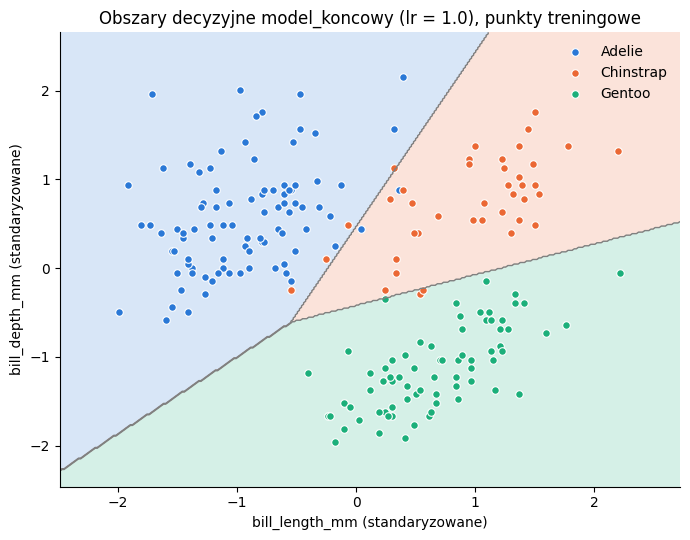

In [12]:
najlepsze_lr = wyniki_lr["val loss"].idxmin()
print("wybrane lr (na podstawie walidacji):", najlepsze_lr)

model_koncowy, _ = train(najlepsze_lr)
model_koncowy.eval()
with torch.no_grad():
    logits_te = model_koncowy(X_te)
acc_test = (logits_te.argmax(dim=1) == y_te).float().mean().item()
print(f"acc_test = {acc_test:.4f}")

sk = LogisticRegression().fit(X_tr.numpy(), y_tr.numpy())
acc_sk = sk.score(X_te.numpy(), y_te.numpy())
print(f"acc_sk   = {acc_sk:.4f}")

p_test = torch.softmax(logits_te[:5], dim=1)
tabela = pd.DataFrame(p_test.numpy(), columns=gatunki).round(3)
tabela["prawdziwy"] = [gatunki[i] for i in y_te[:5]]
tabela["przewidziany"] = [gatunki[i] for i in p_test.argmax(dim=1)]
print(tabela)


def granica(model, X, y, tytul=""):
  kolory = ["#2a78d6", "#eb6834", "#1baf7a"]
  x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
  y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
  xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
  siatka = torch.tensor(np.c_[xx.ravel(), yy.ravel()], dtype=torch.float32)
  with torch.no_grad():
    klasy = model(siatka).argmax(dim=1).numpy().reshape(xx.shape)

  fig, ax = plt.subplots(figsize=(7, 5.5))
  ax.contourf(xx, yy, klasy, levels=[-0.5, 0.5, 1.5, 2.5],
              cmap=ListedColormap(kolory), alpha=0.18)
  ax.contour(xx, yy, klasy, levels=[0.5, 1.5], colors="gray", linewidths=1)
  for k, (nazwa, kolor) in enumerate(zip(gatunki, kolory)):
    m = y == k
    ax.scatter(X[m, 0], X[m, 1], s=30, color=kolor, edgecolor="white",
                linewidth=0.8, label=nazwa)
  ax.set(title=tytul, xlabel="bill_length_mm (standaryzowane)",
          ylabel="bill_depth_mm (standaryzowane)")
  ax.legend(frameon=False)
  ax.spines[["top", "right"]].set_visible(False)
  fig.tight_layout()
  plt.show()


granica(model_koncowy, X_tr.numpy(), y_tr.numpy(),
        tytul=f"Obszary decyzyjne model_koncowy (lr = {najlepsze_lr}), punkty treningowe")

In [13]:
# TEST
assert 0.85 < acc_test <= 1.0
assert abs(acc_test - acc_sk) <= 0.06, "Ten sam model - wyniki powinny być bardzo podobne"
assert torch.allclose(p_test.sum(dim=1), torch.ones(5))
print("6 OK")

6 OK


*Twoja odpowiedź:*
1. Jak wypada Twój model w porównaniu ze scikit-learn? Czy to zaskakujące?
2. Gdzie leżą błędy modelu na wykresie obszarów decyzyjnych? Czy model liniowy mógłby tu zrobić coś lepiej?
3. Wymień kroki pętli uczenia i powiedz jednym zdaniem, co robi każdy z nich.

> 1. Mój model ma 0.957 na teście, a scikit-learn - 0.928. Czyli różnica to 2 pingwiny z 69. To nie zaskakuje.

> 2. Na styku Adelie i Chinstrap: kilka Chinstrapów wpada w obszar Adelie, i kilka Adelie w obszar Chinstrap. Pojedyńcze Gentoo leży przy granicy z Chinstrap. Model liniowy nie zrobi tu wiele lepiej. Pomóc mogłyby dodatkowe cechy albo model nieliniowy.

> 3. Kroki pętli uczenia: <ul>
    <li>for xb, yb in loader: dzieli dane na losowo przetasowane mini-batche po 32 przykłady.</li>
    <li>optimizer.zero_grad(): zeruje gradienty z poprzedniego kroku, bo PyTorch domyślnie je sumuje.</li>
    <li>model(xb): liczy logity dla batcha (forward pass).</li>
    <li>loss_fn(...) porównuje logity z prawdziwymi etykietami i daje jedną liczbę: stratę.</li>
    <li>loss.backward(): liczy gradient straty względem wag i biasu (propagacja wsteczna).</li>
    <li>optimizer.step(): przesuwa wagi o lr razy gradientw kierunku mniejszej straty.</li>
    <li>Ewaluacja po epoce (model.eval(), torch.no_grad()): liczy stratę i accuracy na train i val bez zmieniania wag i zapisuje je w historia.</li>
</ul>

---
## 7. Dla chętnych
1. **Batch size:** naucz model z `lr=0.1` dla `batch_size` ∈ {8, 32, 204} (204 = cały zbiór naraz). Porównaj krzywe straty. Który wariant robi najwięcej kroków w epoce? Który uczy się najszybciej w przeliczeniu na epoki?
2. **Adam:** zamień `optim.SGD` na `optim.Adam` (lr = 0.01) i porównaj krzywe z SGD.
3. **Więcej cech:** dodaj `flipper_length_mm` i `body_mass_g` (`nn.Linear(4, 3)`). Ile zyskuje accuracy?